In [1]:
from model import VAE_Encoder_MNIST,Ganerator_MNIST
import torch
from torchvision import datasets, transforms
from torchvision.utils import save_image
import numpy as np
import matplotlib.pyplot as plt
from torchvision.utils import make_grid
from com_utils import array_to_bits
from scipy.io import savemat
import os

In [2]:
device = "cuda" if torch.cuda.is_available() else "cpu"

transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.5,), (0.5,))
])

dataset = datasets.FashionMNIST(
    root="D:/Python/SemCom/saved_data",
    train=True,
    download=False,
    transform=transform
)

# dataloader
dl = torch.utils.data.DataLoader(dataset, batch_size=64, shuffle=False)

fixed_x, _ = next(iter(dl))
fixed_x = fixed_x[:64].to(device)


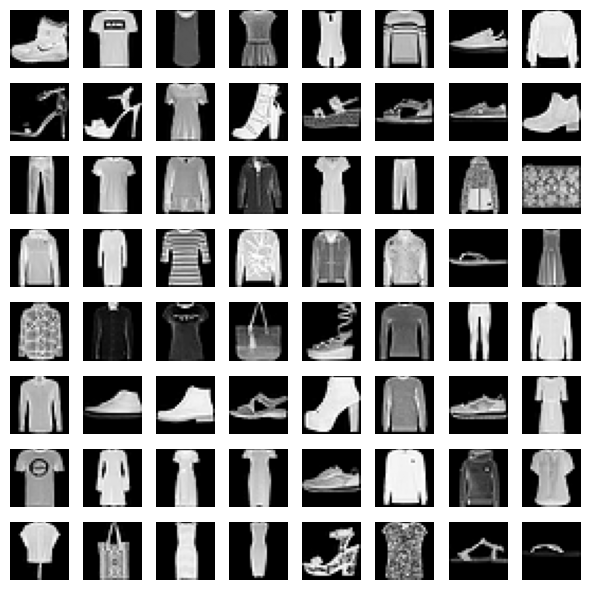

In [3]:
# original data
plt.figure(figsize=(6,6))

for i in range(64):
    plt.subplot(8, 8, i+1)
    plt.imshow(fixed_x[i].cpu().squeeze().numpy(), cmap='gray')
    plt.axis("off")

plt.tight_layout()
plt.show()

In [4]:
# encoder
z_dim = 64
E = VAE_Encoder_MNIST(latent_dim=z_dim).to(device)
E.load_state_dict(torch.load("./save_model/E_invert_to_G_F.pth"))
E.eval()
for p in E.parameters():
    p.requires_grad = False

In [5]:
G = Ganerator_MNIST(z_dim=z_dim).to(device)
G.load_state_dict(torch.load("./save_model/G_wgangp_C.pth"))
G.eval()
for p in G.parameters():
    p.requires_grad = False

In [6]:
# encode
with torch.no_grad():
    mu, logvar = E(fixed_x)
    z = mu

# 存 latent
z_np = z.detach().cpu().numpy()
# np.save("z_batch.npy", z_np)

print("z shape =", z.shape)
print("z =", z)

z shape = torch.Size([64, 64])
z = tensor([[-0.0609,  0.5086,  1.4428,  ...,  1.3850,  1.6067, -1.6071],
        [-1.4115,  1.3989,  0.1375,  ...,  0.4019,  1.5869,  0.3517],
        [-0.2585, -0.2100,  0.3494,  ...,  0.2614, -0.1765, -0.6236],
        ...,
        [-0.4697,  1.2713, -0.5302,  ...,  0.4834, -0.2818,  0.1444],
        [-0.7918,  0.1833,  0.5184,  ...,  2.4927, -0.8237, -0.1044],
        [-0.2623, -0.8020, -0.1092,  ...,  2.8318, -0.2851, -0.9773]],
       device='cuda:0')


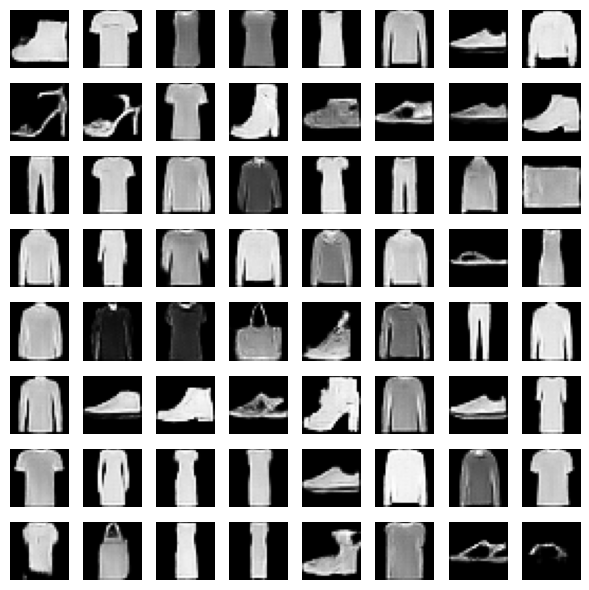

In [7]:
z_in = z.view(z.size(0), z.size(1), 1, 1)
# reconstruct
with torch.no_grad():
    x_gen_orig = G(z_in)

plt.figure(figsize=(6,6))

for i in range(64):
    plt.subplot(8, 8, i+1)
    img = ((x_gen_orig[i] + 1) / 2).cpu().squeeze().numpy()
    plt.imshow(img, cmap='gray')
    plt.axis("off")

plt.tight_layout()
plt.show()

save_image((fixed_x.cpu() + 1) / 2, "fixed_x_debug.png", nrow=8)

In [8]:
# quantization tensor
# [-128,127]
bits = 8
qmax = 2**(bits-1) - 1
qmin = -2**(bits-1)

scale = z.abs().max() / qmax

z_q = torch.round(z / scale).clamp(qmin, qmax).to(torch.int8)

# recover
z_rec = z_q.float() * scale

In [9]:
print("original z:")
print(z)

print("quantized:")
print(z_q)

print("reconstructed:")
print(z_rec)

mse = torch.mean((z - z_rec)**2)
print("MSE:", mse.item())

original z:
tensor([[-0.0609,  0.5086,  1.4428,  ...,  1.3850,  1.6067, -1.6071],
        [-1.4115,  1.3989,  0.1375,  ...,  0.4019,  1.5869,  0.3517],
        [-0.2585, -0.2100,  0.3494,  ...,  0.2614, -0.1765, -0.6236],
        ...,
        [-0.4697,  1.2713, -0.5302,  ...,  0.4834, -0.2818,  0.1444],
        [-0.7918,  0.1833,  0.5184,  ...,  2.4927, -0.8237, -0.1044],
        [-0.2623, -0.8020, -0.1092,  ...,  2.8318, -0.2851, -0.9773]],
       device='cuda:0')
quantized:
tensor([[ -1,  12,  35,  ...,  33,  38, -38],
        [-34,  33,   3,  ...,  10,  38,   8],
        [ -6,  -5,   8,  ...,   6,  -4, -15],
        ...,
        [-11,  30, -13,  ...,  12,  -7,   3],
        [-19,   4,  12,  ...,  60, -20,  -2],
        [ -6, -19,  -3,  ...,  68,  -7, -23]], device='cuda:0',
       dtype=torch.int8)
reconstructed:
tensor([[-0.0418,  0.5015,  1.4627,  ...,  1.3791,  1.5881, -1.5881],
        [-1.4209,  1.3791,  0.1254,  ...,  0.4179,  1.5881,  0.3343],
        [-0.2507, -0.2090,  0.33

In [10]:
# generator
z_in = z.view(z.size(0), z.size(1), 1, 1)
z_rec_in = z_rec.view(z_rec.size(0), z_rec.size(1), 1, 1)

# reconstruct
with torch.no_grad():
    x_gen_orig = G(z_in)
    x_gen_rec = G(z_rec_in)

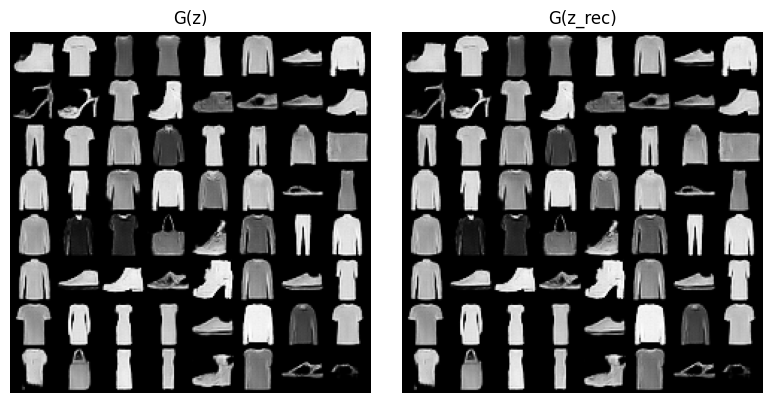

In [11]:
fig, ax = plt.subplots(1, 2, figsize=(8,4))

# G(z)
grid1 = make_grid((x_gen_orig + 1) / 2, nrow=8)
img1 = grid1.permute(1,2,0).cpu().numpy()

# G(z_rec)
grid2 = make_grid((x_gen_rec + 1) / 2, nrow=8)
img2 = grid2.permute(1,2,0).cpu().numpy()

ax[0].imshow(img1, cmap='gray')
ax[0].set_title("G(z)")
ax[0].axis("off")

ax[1].imshow(img2, cmap='gray')
ax[1].set_title("G(z_rec)")
ax[1].axis("off")

plt.tight_layout()
plt.show()


In [12]:
# 這裡停在測試完VAE encoder 做完 encode 
# 做量化
# 做復原然後做量化前後對比
# 解決問題:
#   1. transformer的不同會造成解出的結果有誤差
#   2. 有無normalization也有差
# 待解決: 
#   1. 要不要對gan也新增label來提升encoder對於 decode的結果做提升，畢竟DM都需要label了
#      是否passdown 的差別而已
# 2026.03.11

In [13]:
# 統計經過encode後的數據
# 1.先統計每個data經過code之後的數據
# 2.做8 bits(256)、7 bits(128)、6 bits(64)、5 bits(32)的uniform quantization
all_z = []

E.eval()

with torch.no_grad():
    for x, _ in dl:

        x = x.to(device)

        mu, logvar = E(x)   # VAE encoder
        z = mu              # 通常 encode 用 mean

        all_z.append(z.cpu())

all_z = torch.cat(all_z, dim=0)

print("latent shape:", all_z.shape)
print("min:", all_z.min())
print("max:", all_z.max())
print("mean:", all_z.mean())
print("std:", all_z.std())

latent shape: torch.Size([60000, 64])
min: tensor(-6.8110)
max: tensor(7.0037)
mean: tensor(-0.0375)
std: tensor(0.9784)


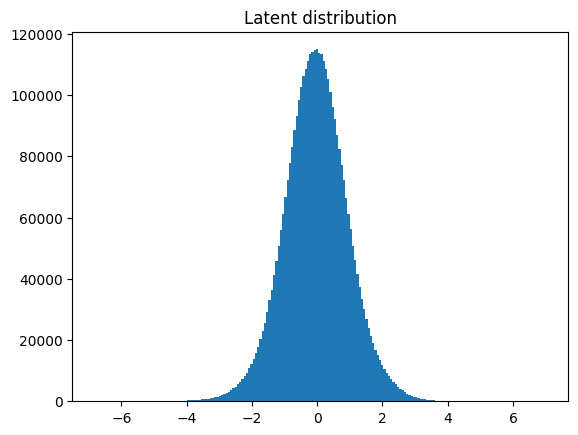

In [14]:
plt.hist(all_z.flatten().numpy(), bins=200)
plt.title("Latent distribution")
plt.show()

In [15]:
# scale = torch.tensor(4)
scale = all_z.abs().max() / qmax
print
print(scale)
print(qmax)
print(qmin)

tensor(0.0551)
127
-128


In [16]:
# quantization tensor
# 
bits = 8
qmax = 2**(bits-1) - 1
qmin = -2**(bits-1)

scale = all_z.abs().max() / qmax
print("\n===== Quantization Scale =====")
print('[',qmin,',',qmax,']')
print("max:")
print(all_z.abs().max())
print('scale:')
print(scale)

z_q = torch.round(all_z / scale).clamp(qmin, qmax).to(torch.int8)

# recover
z_rec = z_q.float() * scale

latent_mse = torch.mean((all_z - z_rec) ** 2)
latent_mae = torch.mean(torch.abs(all_z - z_rec))

# generator
z_in = all_z.view(all_z.size(0), all_z.size(1), 1, 1).to(device)
z_rec_in = z_rec.view(z_rec.size(0), z_rec.size(1), 1, 1).to(device)

# reconstruct
with torch.no_grad():
    x_gen_orig = G(z_in)
    x_gen_rec = G(z_rec_in)

img_mse = torch.mean((x_gen_orig - x_gen_rec) ** 2)
img_mae = torch.mean(torch.abs(x_gen_orig - x_gen_rec))

print("\n===== Image comparison =====")
print("x_gen_orig shape:", x_gen_orig.shape)
print("x_gen_rec shape:", x_gen_rec.shape)
print("Image MSE:", img_mse.item())
print("Image MAE:", img_mae.item())

idx = 0
print("\n===== Example latent =====")
print("original all_z[0]:")
print(all_z[idx])

print("\nquantized z_q[0]:")
print(z_q[idx])

print("\nreconstructed z_rec[0]:")
print(z_rec[idx])



===== Quantization Scale =====
[ -128 , 127 ]
max:
tensor(7.0037)
scale:
tensor(0.0551)

===== Image comparison =====
x_gen_orig shape: torch.Size([60000, 1, 28, 28])
x_gen_rec shape: torch.Size([60000, 1, 28, 28])
Image MSE: 0.0004549604782368988
Image MAE: 0.007234725635498762

===== Example latent =====
original all_z[0]:
tensor([-0.0609,  0.5086,  1.4428,  0.9622, -1.1890,  0.2728, -0.1951, -0.2892,
        -0.9848, -1.7254, -2.0392,  2.2118,  0.1483,  0.9058,  0.1474,  1.0735,
        -1.3498, -0.3325, -1.3920,  0.3403, -0.5265,  1.8094, -0.3808, -0.2485,
        -1.3052,  0.2285,  0.9628,  0.9245,  0.6927, -0.1852, -1.2039,  0.2525,
         2.4443, -1.0283,  0.0851, -1.3564,  0.2651, -0.0454,  0.1269,  0.4255,
         1.9019,  0.0918,  0.1341, -0.7648,  0.3878, -0.6383,  1.4549, -0.0853,
        -0.2920,  0.1660, -1.5877, -0.1050,  1.2753, -1.6969,  0.3960,  1.6406,
        -0.2583, -0.3715, -0.8006, -0.7233,  1.0904,  1.3850,  1.6067, -1.6071])

quantized z_q[0]:
tensor([ -1,

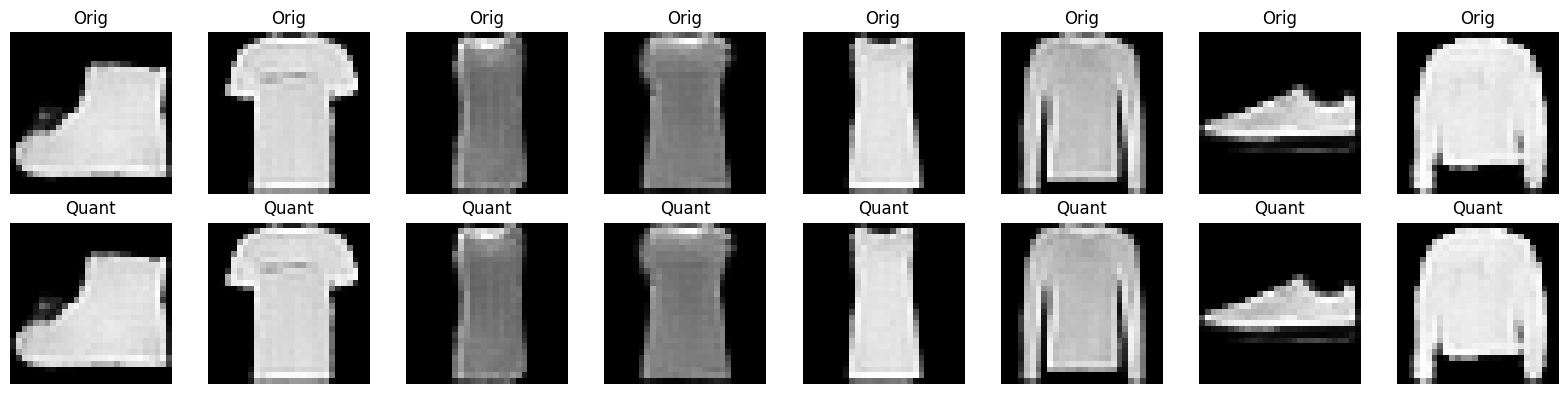

In [17]:
n_show = 8

orig_show = x_gen_orig[:n_show].detach().cpu()
rec_show  = x_gen_rec[:n_show].detach().cpu()

fig, axes = plt.subplots(2, n_show, figsize=(2*n_show, 4))

for i in range(n_show):
    axes[0, i].imshow(orig_show[i].squeeze(), cmap='gray')
    axes[0, i].axis('off')
    axes[0, i].set_title("Orig")

    axes[1, i].imshow(rec_show[i].squeeze(), cmap='gray')
    axes[1, i].axis('off')
    axes[1, i].set_title("Quant")

plt.tight_layout()
plt.show()

In [18]:
# 做量化對還原的影響
# 從8bits到3bits 
# 大概到4bits的時候會有比較顯著的錯誤出現
# 統計結果是高斯分布 max在4 min是-4
# 2026.03.13

In [25]:
E.eval()

bits = 3

save_dir = F"latent_bits_F/bits_{bits}"
os.makedirs(save_dir, exist_ok=True)

qmax = 2**(bits-1) - 1
qmin = -2**(bits-1)

dataset = dl.dataset
N = len(dataset)

for i in range(200):

    # ------------------------
    # 隨機抽一張圖
    # ------------------------
    idx = np.random.randint(0, N)
    x, _ = dataset[idx]

    x = x.unsqueeze(0).to(device)

    # ------------------------
    # encode
    # ------------------------
    with torch.no_grad():
        mu, logvar = E(x)
        z = mu.squeeze(0)

    # ------------------------
    # quantization
    # ------------------------
    scale = z.abs().max() / qmax
    z_q = torch.round(z / scale).clamp(qmin, qmax).to(torch.int8)

    # ------------------------
    # 轉 bit
    # ------------------------
    bits_array = array_to_bits(z_q, bit_width=bits)

    # ------------------------
    # 存 MAT
    # ------------------------
    savemat(
        f"{save_dir}/sample_{i:03d}.mat",
        {"bits": bits_array.astype(np.float64)}  # MATLAB double 0/1
    )

    print(f"saved {i}")

saved 0
saved 1
saved 2
saved 3
saved 4
saved 5
saved 6
saved 7
saved 8
saved 9
saved 10
saved 11
saved 12
saved 13
saved 14
saved 15
saved 16
saved 17
saved 18
saved 19
saved 20
saved 21
saved 22
saved 23
saved 24
saved 25
saved 26
saved 27
saved 28
saved 29
saved 30
saved 31
saved 32
saved 33
saved 34
saved 35
saved 36
saved 37
saved 38
saved 39
saved 40
saved 41
saved 42
saved 43
saved 44
saved 45
saved 46
saved 47
saved 48
saved 49
saved 50
saved 51
saved 52
saved 53
saved 54
saved 55
saved 56
saved 57
saved 58
saved 59
saved 60
saved 61
saved 62
saved 63
saved 64
saved 65
saved 66
saved 67
saved 68
saved 69
saved 70
saved 71
saved 72
saved 73
saved 74
saved 75
saved 76
saved 77
saved 78
saved 79
saved 80
saved 81
saved 82
saved 83
saved 84
saved 85
saved 86
saved 87
saved 88
saved 89
saved 90
saved 91
saved 92
saved 93
saved 94
saved 95
saved 96
saved 97
saved 98
saved 99
saved 100
saved 101
saved 102
saved 103
saved 104
saved 105
saved 106
saved 107
saved 108
saved 109
saved 110


In [26]:
print(bits_array)

[0 0 0 0 1 0 0 0 0 0 0 0 1 1 1 1 1 1 1 1 1 1 0 0 1 1 1 1 0 0 1 1 1 0 0 0 0
 1 1 0 0 0 0 0 0 1 1 1 1 1 1 0 0 0 0 0 0 0 0 0 1 0 0 0 0 0 0 0 0 1 1 1 1 1
 1 1 1 1 0 0 0 1 1 1 1 0 0 1 1 1 0 0 0 0 0 0 1 1 1 1 0 0 0 0 0 0 0 0 1 0 1
 0 1 1 0 0 0 0 0 0 1 1 1 1 1 1 0 1 0 0 0 0 1 1 1 1 1 1 0 0 0 0 1 1 1 1 1 1
 1 1 0 1 1 1 0 0 0 0 0 1 1 1 0 1 1 0 0 0 0 0 0 1 1 1 1 1 1 0 1 0 0 0 0 1 0
 0 1 0 0 0 0 0]
